In [107]:
"""📝 Project Brief: The "Profit Preservation" Initiative
Company: Global-Mart Retail Solutions Role: Junior Data Analyst

Stakeholder: Chief Operations Officer (COO)

1. Executive Summary
While Global-Mart has seen a 12% increase in Gross Sales over the last fiscal year, our Net Profit Margins are stagnating. 
Preliminary audits suggest that "hidden costs"—specifically high product return rates and regional logistics inefficiencies—are eroding our gains.

We have provided you with six core datasets.
Your mission is to identify where the "leakage" is happening and provide actionable recommendations to stop it.

2. The Core Business Problem
We are currently flying blind. We don't know if our losses are due to bad products, poor store management, or disloyal customer segments.

Your specific objectives are:

Identify "High-Risk" Products: Which items have a return rate exceeding our 10% threshold?

Audit Regional Performance: Are specific r
egions underperforming due to high return volumes or low average transaction values?

Segment the Customer Base: 
Distinguish between our "High-Value Loyalists" and "Serial Returners" who may be costing the company money in shipping and restocking.

3. Data Assets Provided
You have access to the following relational tables:

Transactions: The heartbeat of the business (Sales, Dates, Quantities).

Returns: The "leakage" data (Linked to Transactions).

Product: Categories, Sub-categories, and Base Prices.

Store: Location details and Store types.

Region: Geographical hierarchy (North, South, East, West).

Customer: Demographics and signup dates.

4. Deliverables Expected
A Cleaned Master Dataset: A joined view showing the "Net Revenue" (Sales minus Returns).

The "Profit Leak" Dashboard: Visualizations highlighting the top 5 worst-performing products and regions.

The "Executive Summary": 3-5 bullet points explaining why we are losing money and how to fix it (e.g., "Discontinue Product X in the North Region").

5. Success Metric
A successful project will provide a clear answer to: "If we could change three things tomorrow to increase profit by 5%, what would they be?"

Now that you have your "Boss's" instructions, how would you like to handle the first task?

Option A: I can write the SQL Join Query to combine these 6 tables into one "Master Table."

Option B: I can provide the Python (Pandas) code to calculate the "Return Rate" across all your products.

Option C: I can list the Top 5 Visualizations you should build to answer this brief."""
import pandas as pd 


df_customer= pd.read_csv(r"C:\Users\paree\OneDrive\Documents\.ipynb_checkpoints\Sales Dataset\Customers.csv")
df_product= pd.read_csv(r"C:\Users\paree\OneDrive\Documents\.ipynb_checkpoints\Sales Dataset\Products.csv")
df_region = pd.read_csv(r"C:\Users\paree\OneDrive\Documents\.ipynb_checkpoints\Sales Dataset\Regions.csv")
df_return = pd.read_csv(r"C:\Users\paree\OneDrive\Documents\.ipynb_checkpoints\Sales Dataset\Returns_1997-1998.csv")
df_store = pd.read_csv(r"C:\Users\paree\OneDrive\Documents\.ipynb_checkpoints\Sales Dataset\Stores.csv")
df_transaction = pd.read_csv(r"C:\Users\paree\OneDrive\Documents\.ipynb_checkpoints\Sales Dataset\Transactions_1997.csv")
df_transaction2 = pd.read_csv(r"C:\Users\paree\OneDrive\Documents\.ipynb_checkpoints\Sales Dataset\Transactions_1998.csv")

In [108]:
df_customer.fillna(value =' ',inplace=True)

In [109]:
df_transactions = pd.concat([df_transaction,df_transaction2])

In [110]:
df_transactions


,transaction_date,stock_date,product_id,customer_id,store_id,quantity
0,1/1/1997,12/31/1996,869,3449,6,5
1,1/1/1997,12/31/1996,1472,3449,6,3
2,1/1/1997,12/28/1996,76,3449,6,4
3,1/1/1997,12/26/1996,320,3449,6,3
4,1/1/1997,12/25/1996,4,3449,6,4
...,...,...,...,...,...,...
182878,12/30/1998,12/29/1998,1521,7197,11,3
182879,12/30/1998,12/23/1998,1536,5223,10,2
182880,12/30/1998,12/23/1998,1542,8077,10,4
182881,12/30/1998,12/28/1998,1544,4485,10,2


In [111]:
#The Question: "Which regions or product categories are bleeding money due to high return rates?
df_return['return_date'] = pd.to_datetime(df_return['return_date'],format ="%m/%d/%Y")

In [112]:
df_transactions['transaction_date'] = pd.to_datetime(df_transactions['transaction_date'],format = 'mixed')

In [113]:
df_transactions['stock_date'] = pd.to_datetime(df_transactions['stock_date'],format = 'mixed')

In [114]:
a = df_return.groupby('product_id')['quantity'].sum()
a = df_return.sort_values(by ='quantity',ascending = False ).reset_index().head()

In [116]:
df_product.head()

,product_id,product_brand,product_name,product_sku,product_retail_price,product_cost,product_weight,recyclable,low_fat
0,1,Washington,Washington Berry Juice,90748583674,2.85,0.94,8.39,NaN,NaN
1,2,Washington,Washington Mango Drink,96516502499,0.74,0.26,7.42,NaN,1.0
2,3,Washington,Washington Strawberry Drink,58427771925,0.83,0.40,13.10,1.0,1.0
3,4,Washington,Washington Cream Soda,64412155747,3.64,1.64,10.60,1.0,NaN
4,5,Washington,Washington Diet Soda,85561191439,2.19,0.77,6.66,1.0,NaN


In [117]:
df_customer.columns

Index(['customer_id', 'customer_acct_num', 'first_name', 'last_name',
       'customer_address', 'customer_city', 'customer_state_province',
       'customer_postal_code', 'customer_country', 'birthdate',
       'marital_status', 'yearly_income', 'gender', 'total_children',
       'num_children_at_home', 'education', 'acct_open_date', 'member_card',
       'occupation', 'homeowner', 'upgrade'],
      dtype='object')

In [118]:
df_store.columns

Index(['store_id', 'region_id', 'store_type', 'store_name',
       'store_street_address', 'store_city', 'store_state', 'store_country',
       'store_phone', 'first_opened_date', 'last_remodel_date', 'total_sqft',
       'grocery_sqft'],
      dtype='object')

In [120]:
df_transaction.groupby('product_id')['quantity'].sum()

product_id
1        83
2       171
3       151
4       155
5       134
       ... 
1555    163
1556    178
1557    171
1558    185
1559     79
Name: quantity, Length: 1559, dtype: int64

In [121]:
df_return.columns

Index(['return_date', 'product_id', 'store_id', 'quantity'], dtype='object')

In [122]:
df_product.columns

Index(['product_id', 'product_brand', 'product_name', 'product_sku',
       'product_retail_price', 'product_cost', 'product_weight', 'recyclable',
       'low_fat'],
      dtype='object')

In [123]:
df_transaction.columns

Index(['transaction_date', 'stock_date', 'product_id', 'customer_id',
       'store_id', 'quantity'],
      dtype='object')

In [124]:
#to check the how many prdouct transaction have and quantiies
sales_summary = df_transaction.groupby('product_id')['quantity'].sum().reset_index()

In [125]:
# to check th esame thing product id and quantities in retrun how many are return 
return_summary = df_return.groupby("product_id")["quantity"].sum().reset_index()

In [126]:
df_comparison = pd.merge(sales_summary,return_summary,on = 'product_id', how = 'left')

In [127]:
df_comparison = df_comparison.rename(columns = {
                                  'quantity_x':'units_sold',
                                   'quantity_y':'units_returned'})

In [128]:
df_comparison

,product_id,units_sold,units_returned
0,1,83,3.0
1,2,171,4.0
2,3,151,9.0
3,4,155,7.0
4,5,134,1.0
...,...,...,...
1554,1555,163,7.0
1555,1556,178,4.0
1556,1557,171,4.0
1557,1558,185,2.0


In [129]:
df_comparison.isnull().sum()

product_id         0
units_sold         0
units_returned    20
dtype: int64

In [130]:
# i am using fill na bcs if the units_returned is nan in 20 places means that it doesnt return by customer so we can give that palce 0 wrether than nan
df_comparison['units_returned'] = df_comparison['units_returned'].fillna(0)

In [131]:
# now calculate the high retrun rate above then 10% 
df_comparison['return_rate%'] = ((df_comparison['units_returned']/df_comparison['units_sold'])*100).round(2)

In [132]:
df_comparison.isnull().sum()

product_id        0
units_sold        0
units_returned    0
return_rate%      0
dtype: int64

In [134]:
# now in our df we dont have name of product so now correct this
# We just want the 'dictionary' of IDs and Names
df_comparison = pd.merge(df_comparison, (df_product[['product_id','product_name']]), on='product_id', how='left')
df_comparison

,product_id,units_sold,units_returned,return_rate%,product_name
0,1,83,3.0,3.61,Washington Berry Juice
1,2,171,4.0,2.34,Washington Mango Drink
2,3,151,9.0,5.96,Washington Strawberry Drink
3,4,155,7.0,4.52,Washington Cream Soda
4,5,134,1.0,0.75,Washington Diet Soda
...,...,...,...,...,...
1554,1555,163,7.0,4.29,CDR Strawberry Jam
1555,1556,178,4.0,2.25,CDR Creamy Peanut Butter
1556,1557,171,4.0,2.34,CDR Strawberry Preserves
1557,1558,185,2.0,1.08,CDR Extra Chunky Peanut Butter


In [141]:
toprisk_5 = df_comparison[['return_rate%','product_name']].sort_values( by='return_rate%', ascending = False).reset_index().head()
toprisk_5.to_csv('toprisk_5.csv', index=False)


In [147]:
import pandas as pd

# 1. Separate Sales and Returns
# Using 'df_transactions' consistently to avoid the NameError
sales = df_transactions[df_transactions['quantity'] > 0]
returns = df_transactions[df_transactions['quantity'] < 0].copy()

# 2. Convert negative return quantities to positive for calculation
returns['quantity'] = returns['quantity'].abs()

# 3. Aggregate totals per product
total_sold = sales.groupby('product_id')['quantity'].sum()
total_returned = returns.groupby('product_id')['quantity'].sum()

# 4. Create a metrics DataFrame
# .fillna(0) ensures products with 0 returns don't break the math
df_metrics = pd.DataFrame({
    'total_sold': total_sold, 
    'total_returned': total_returned
}).fillna(0)

# 5. Calculate Return Rate (%)
df_metrics['return_rate'] = (df_metrics['total_returned'] / df_metrics['total_sold']) * 100

# 6. Filter for "High-Risk" ( > 10% return rate)
high_risk_ids = df_metrics[df_metrics['return_rate'] > 10].reset_index()

# 7. Merge with the product table to get names and brands
high_risk_products = high_risk_ids.merge(
    df_product[['product_id', 'product_brand', 'product_name']], 
    on='product_id'
)

# Display results sorted by highest risk
print(high_risk_products[['product_name', 'product_brand', 'return_rate']].sort_values(by='return_rate', ascending=False))

Empty DataFrame
Columns: [product_name, product_brand, return_rate]
Index: []


In [73]:
## --- Problem 2: Regional Performance Audit (Integrated) ---

# 1. Summarize total sales per store
store_sale = df_transaction.groupby('store_id')['quantity'].sum().reset_index()
store_sale = store_sale.rename(columns={'quantity': 'totalsales_perstore'})

# 2. Create a clean Region/District lookup table from df_return
# We grab the names and use .drop_duplicates() so each region_id appears only once.
region_lookup = df_region[['region_id', 'sales_district', 'sales_region']].drop_duplicates()

# 3. Build the Master List (Store info + Sales)
# We use df_store as the anchor to ensure all 23 stores are included.
stores_sales_info = pd.merge(
    df_store[['store_id', 'region_id', 'store_name']], 
    store_sale, 
    on='store_id', 
    how='left'
)

# 4. Attach the Sales District and Sales Region names
# Now we map the 'sales_district' to the table using the 'region_id'
stores_sales_info = pd.merge(stores_sales_info, region_lookup, on='region_id', how='left')

# 5. Summarize total returns per store
storewise_return = df_return.groupby("store_id")["quantity"].sum().reset_index()
storewise_return = storewise_return.rename(columns={'quantity': 'totalreturn_perstore'})

# 6. Combine everything into the final audit table
final_region_audit = pd.merge(stores_sales_info, storewise_return, on='store_id', how='left').fillna(0)

# 7. Data Cleaning: Convert floats to integers
final_region_audit['totalsales_perstore'] = final_region_audit['totalsales_perstore'].astype(int)
final_region_audit['totalreturn_perstore'] = final_region_audit['totalreturn_perstore'].astype(int)

print(final_region_audit)
final_region_audit.to_csv('final_region_audit.csv', index=False)


    store_id  region_id store_name  totalsales_perstore sales_district  \
0          1         28    Store 1                    0       Acapulco   
1          2         78    Store 2                 2237     Bellingham   
2          3         76    Store 3                24576      Bremerton   
3          4         27    Store 4                    0        Camacho   
4          5          4    Store 5                    0    Guadalajara   
5          6         47    Store 6                21333    Los Angeles   
6          7          3    Store 7                25663    Los Angeles   
7          8         26    Store 8                    0         Marida   
8          9          2    Store 9                    0    Mexico City   
9         10         24   Store 10                    0        Orizaba   
10        11         22   Store 11                26079       Portland   
11        12         25   Store 12                    0        Hidalgo   
12        13         23   Store 13    

In [32]:
## --- Problem 3: Segment the Customer Base ---

# 1. Start with a Master Customer List and link it to Transactions
# We use df_customer first to ensure we account for everyone, then join transaction data.
customer_transactions = pd.merge(
    df_customer[['customer_id', 'first_name', 'last_name']], 
    df_transaction[['product_id', 'customer_id', 'quantity']], 
    on='customer_id', 
    how='left'
).fillna(0)

# 2. Merge with Product Comparison data
# This brings in 'units_sold' and 'units_returned' per product to see the history.
full_customer_history = pd.merge(
    customer_transactions,
    df_comparison.drop(columns=['product_name']), # Drop name to avoid clutter
    on='product_id',
    how='left'
).fillna(0)

# 3. Aggregate: Combine repeated entries into a "One Row Per Customer" summary
customer_summary = full_customer_history.groupby('customer_id').agg({
    'units_sold': 'sum',           # Total items they successfully bought
    'units_returned': 'sum',       # Total items they returned
    'product_id': 'nunique'        # Count of unique products interacted with
}).reset_index()

# Rename for clarity
customer_summary = customer_summary.rename(columns={'product_id': 'unique_product_count'})

# 4. Calculate Return Rate (%) to find High-Value vs. High-Risk
# We replace 0 sales with 1 to avoid math errors (division by zero)
customer_summary['return_rate%'] = (
    customer_summary['units_returned'] / 
    customer_summary['units_sold'].replace(0, 1)
) * 100

# 5. Segment: High-Value Loyalists
# Definition: Bought more than 5 items with a return rate under 10%
loyalists_final = customer_summary[
    (customer_summary['units_sold'] > 5) & 
    (customer_summary['return_rate%'] < 10)
].sort_values(by='units_sold', ascending=False)

# 6. Segment: Serial Returners
# Definition: They have 0 successful sales but have return records
serial_returners_final = customer_summary[
    (customer_summary['units_sold'] == 0) & 
    (customer_summary['units_returned'] > 0)
].sort_values(by='units_returned', ascending=False)

# --- SAVE RESULTS ---
loyalists_final.to_csv('high_value_loyalists.csv', index=False)
serial_returners_final.to_csv('serial_returners.csv', index=False)

print(f"Audit Complete! Found {len(loyalists_final)} Loyalists and {len(serial_returners_final)} Serial Returners.")

Audit Complete! Found 5581 Loyalists and 0 Serial Returners.


In [33]:
loyal_customer = loyalists_final.head(10)
loyal_customer.to_csv('loyal_customer.csv', index=False)

In [41]:
# --- STEP 1: PREPARE THE SALES DATA ---
# Grouping by product_id to get total units sold across all transactions
sales_side = df_transactions.groupby('product_id')['quantity'].sum()

# --- STEP 2: PREPARE THE RETURNS DATA ---
# Grouping by product_id to get total units returned across all return records
return_side = df_return.groupby('product_id')['quantity'].sum()

# --- STEP 3: CREATE THE MASTER JOIN ---
# Joining sales and returns; using 'left' to ensure we keep all products that had sales
# .fillna(0) ensures products with no returns show 0 instead of a blank (NaN) value
both_sides = pd.merge(sales_side, return_side, on='product_id', how='left').fillna(0)

# Renaming columns for clarity: quantity_x came from Sales, quantity_y from Returns
both_sides = both_sides.rename(columns={
    'quantity_x': 'sales_quantity',
    'quantity_y': 'return_quantity'
})

# --- STEP 4: ATTACH PRICING DATA ---
# Bringing in the retail price from the product table to calculate financial impact
net_revenue_table = pd.merge(
    both_sides, 
    df_product[['product_id','product_name', 'product_retail_price']], 
    on='product_id', 
    how='left'
)

# --- STEP 5: FINAL FINANCIAL & RATE CALCULATIONS ---
# Ensure return_quantity is a whole number for clean math
net_revenue_table['return_quantity'] = net_revenue_table['return_quantity'].astype('int64')

# Net Revenue = (Sales - Returns) * Price. This shows the actual money kept.
net_revenue_table['net_revenue'] = (net_revenue_table['sales_quantity'] - net_revenue_table['return_quantity']) * net_revenue_table['product_retail_price']

# Calculate Return Rate Percentage
# Note: We use .replace(0, 1) on the sales_quantity to avoid "Infinity" errors for stores with 0 sales
net_revenue_table['return_rate'] = (net_revenue_table['return_quantity'] / net_revenue_table['sales_quantity'].replace(0, 1)) * 100

# Rounding to 2 decimal places for a professional, readable dashboard view
net_revenue_table['return_rate'] = net_revenue_table['return_rate'].round(2)

# Display the final master dataset
net_revenue_table.to_csv('net_revenue_table.csv', index=False)
print(net_revenue_table)

      product_id  sales_quantity  return_quantity  \
0              1             245                3   
1              2             471                4   
2              3             447                9   
3              4             459                7   
4              5             440                1   
...          ...             ...              ...   
1554        1555             496                7   
1555        1556             566                4   
1556        1557             560                4   
1557        1558             453                2   
1558        1559             240                3   

                        product_name  product_retail_price  net_revenue  \
0             Washington Berry Juice                  2.85       689.70   
1             Washington Mango Drink                  0.74       345.58   
2        Washington Strawberry Drink                  0.83       363.54   
3              Washington Cream Soda                  3.64     

In [75]:
# --- PART 1: TOP 5 WORST PRODUCTS (BY RETURN RATE) ---
# 1. First, ensure the master table itself is rounded
net_revenue_table['return_rate'] = net_revenue_table['return_rate'].round(2)

# 2. Now pick the top 5 (they will already be rounded)
worst_5_products = net_revenue_table.sort_values(by='return_rate', ascending=False).head(5)


# --- PART 2: IDENTIFYING "SLEEPING" REGIONS ---
# Flagging stores with 0 sales
sleeping_region_mask = final_region_audit['totalsales_perstore'] == 0


# --- PART 3: CALCULATING & ROUNDING REGION PERFORMANCE ---
# 1. Calculate the rate
final_region_audit['return_rate'] = (
    (final_region_audit['totalreturn_perstore'] / final_region_audit['totalsales_perstore']) * 100
)

# 2. ROUND IT IMMEDIATELY here to fix the "long decimal" problem in your charts
final_region_audit['return_rate'] = final_region_audit['return_rate'].round(2)


# --- PART 4: FILTERING FOR ACTIVE "PROFIT LEAKS" ---
# Filtering out 0-sale stores to remove 'inf' values
active_regions = final_region_audit[final_region_audit['totalsales_perstore'] > 0].copy()

# Sorting to find the top 5 leaks
worst_5_active_regions = active_regions.sort_values(by='return_rate', ascending=False).head(5)


# --- DISPLAY RESULTS ---
# This will now show clean numbers like '12.45' instead of '12.44999999'
print("Top 5 Toxic Products (Clean Rounded Rates):")
display(worst_5_products[['product_id', 'sales_quantity', 'return_quantity', 'return_rate']])

print("\nTop 5 Active Regions (Clean Rounded Rates):")
display(worst_5_active_regions[['region_id','sales_district', 'totalsales_perstore', 'totalreturn_perstore', 'return_rate']])
worst_5_active_regions.to_csv('worst_5_active_regions.csv', index=False)

Top 5 Toxic Products (Clean Rounded Rates):


,product_id,sales_quantity,return_quantity,return_rate
573,574,478,14,2.93
1431,1432,601,17,2.83
580,581,538,15,2.79
563,564,467,13,2.78
1460,1461,554,15,2.71



Top 5 Active Regions (Clean Rounded Rates):


,region_id,sales_district,totalsales_perstore,totalreturn_perstore,return_rate
15,87,Spokane,23591,559,2.37
14,18,Seattle,25011,547,2.19
22,89,Yakima,11491,250,2.18
16,84,Tacoma,35257,764,2.17
10,22,Portland,26079,564,2.16


<Axes: xlabel='return_rate', ylabel='product_id'>

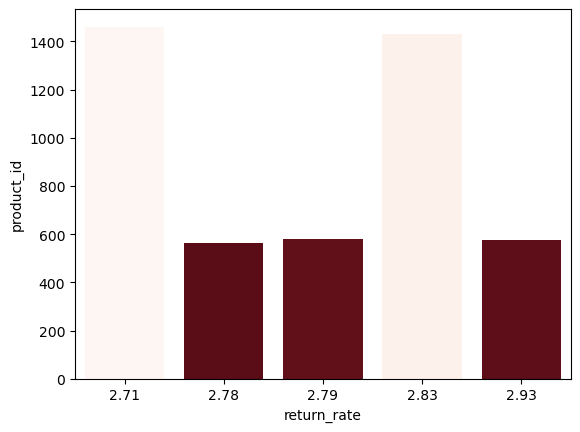

In [36]:
###visualizinng the delivery 2 
# 5 worst products 
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(
    data=worst_5_products, 
    x='return_rate', 
    y='product_id', 
    hue='product_id',   # Assign the Y-variable to 'hue' to fix the warning
    palette='Reds_r', 
    legend=False        # Hide the legend since the Y-axis already tells us the ID
)

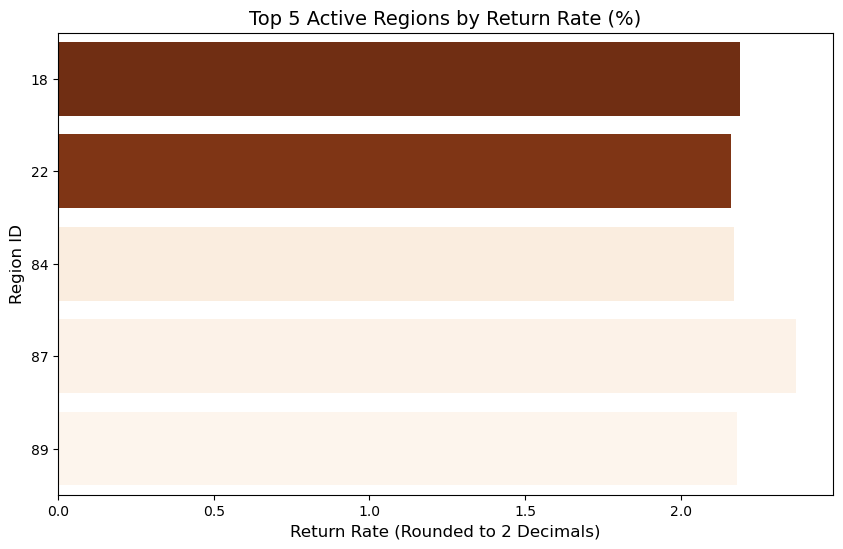

In [37]:
# 1. Round the return_rate inside your 'worst_5' slice specifically
worst_5_active_regions['return_rate'] = worst_5_active_regions['return_rate'].round(2)

# 2. Now plot - the X-axis will now be clean!
plt.figure(figsize=(10, 6)) # Adjusting size for better visibility
sns.barplot(
    data=worst_5_active_regions, 
    x='return_rate', 
    y='region_id', 
    hue='region_id', 
    palette='Oranges_r', 
    orient='h',         # Ensuring horizontal bars for easier reading
    legend=False
)

# 3. Add a Title and Labels
plt.title('Top 5 Active Regions by Return Rate (%)', fontsize=14)
plt.xlabel('Return Rate (Rounded to 2 Decimals)', fontsize=12)
plt.ylabel('Region ID', fontsize=12)

plt.show()